# Lagrangian Duality and Objective–Constraint Geometry

Study how adding redundant box restrictions can change the set of optimal Lagrange multipliers without changing the primal optimizer. The notebook visualizes the attainable objective–constraint pairs by sampling the feasible diamond. The dual analysis is given in Markdown.

[Technical notes](../docs/lagrangian_duality.md) · [Saved figures](../results/lagrangian_duality/)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Monte Carlo sample size

Draw 300,000 points for the geometric illustration; this is not an optimizer.

In [2]:
N = 300000

## Uniform sampling in the enclosing square

Sample each coordinate independently over $[-1,1]$. No random seed is specified, so the plotted point cloud can change on rerun.

In [3]:
x1 = np.random.uniform(-1, 1, N)
x2 = np.random.uniform(-1, 1, N)

## Objective and constraint maps

Let $f(x)=x_1$ and $c(x)=|x_1|+|x_2|$. The inequality is $c(x)\le1$.

In [4]:
c = np.abs(x1) + np.abs(x2)
f = x1

## Filter feasible points

Keep only samples inside the diamond; attainable pairs satisfy $0\le c\le1$ and $-c\le f\le c$.

In [5]:
mask = (c <= 1.0)
c_f = c[mask]
f_f = f[mask]

## Primal optimum

The minimum is attained uniquely at $x^*=(-1,0)$, where $(c^*,f^*)=(1,-1)$.

In [6]:
c_star = 1.0
f_star = -1.0

## Optimal Lagrange multiplier

For the unconstrained domain and inequality $c(x)-1\le0$, the multiplier is $\lambda^*=1$. For the domain restricted to the box, the optimal multiplier is not unique, as derived below.

In [7]:
lambda_star = 1.0

## Plotted line and sign convention

The code plots $f=f^*+\lambda^*(c-c^*)$. With the standard minimization Lagrangian $f+\lambda(c-1)$, the correct supporting line instead has slope $-\lambda^*$: $f=f^*-\lambda^*(c-c^*)$. The plotted line is preserved and should not be mistaken for the correct dual support line.

In [8]:
c_line = np.linspace(0, 1.05, 200)
f_line = f_star + lambda_star * (c_line - c_star)

## Objective–constraint visualization

The scatter illustrates the feasible image; the line is the one actually generated by the implementation.

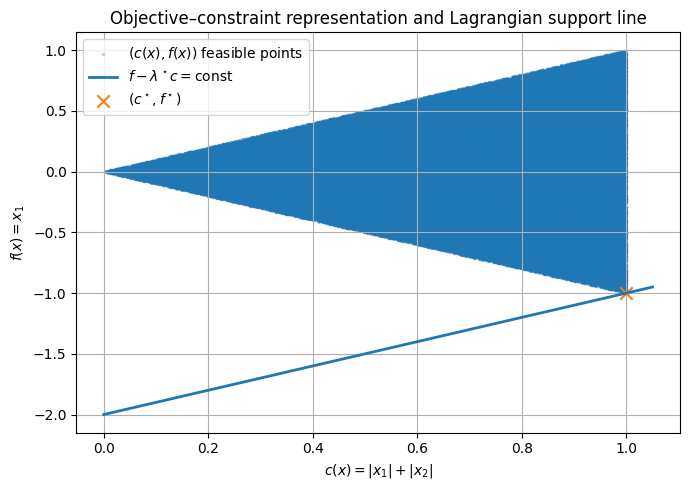

In [11]:
plt.figure(figsize=(7,5))
plt.scatter(c_f, f_f, s=2, alpha=0.25, label=r"$(c(x),f(x))$ feasible points")
plt.plot(c_line, f_line, linewidth=2, label=r"$f-\lambda^\star c = \mathrm{const}$")
plt.scatter([c_star], [f_star], s=80, marker='x', label=r"$(c^\star,f^\star)$")

plt.xlabel(r"$c(x)=|x_1|+|x_2|$")
plt.ylabel(r"$f(x)=x_1$")
plt.title("Objective–constraint representation and Lagrangian support line")
plt.grid(True)
plt.legend()
plt.tight_layout()

# Save figure
plt.savefig("cf_lagrangian_support.png", dpi=300)
plt.show()

## Dual analysis and interpretation

With domain $\mathbb R^2$, the Lagrangian is

$$\mathcal L(x,\lambda)=x_1+\lambda(|x_1|+|x_2|-1),\quad\lambda\ge0.$$

For $\lambda<1$, taking $x_1\to-\infty$ makes the infimum $-\infty$. For $\lambda\ge1$, the infimum is $-\lambda$. Maximizing the dual function therefore gives $\lambda^*=1$ and dual value $-1$.

On the restricted domain $[-1,1]^2$, the box constraints are redundant for primal feasibility, but the dual infimum changes: $q(\lambda)=-1$ for $0\le\lambda\le1$ and $q(\lambda)=-\lambda$ for $\lambda\ge1$. Hence the full interval $[0,1]$ is dual-optimal. Both formulations have primal solution $(-1,0)$ and zero duality gap. The restricted domain changes the multipliers because it changes the minimization used to define the dual function.

**Geometric consistency:** for $\lambda=1$, the correct support line is $f=-c$ (negative slope), coinciding with the lower boundary of the attainable region. The saved figure instead plots $f=c-2$ (positive slope); it passes through the optimum but does not represent the standard Lagrangian level line. The notebook retains that output and its original code. The scatter itself represents both primal feasible sets, which coincide.